K-Means is an distance based algorithm so in some cases the result of the K-Means is not acceptable , Therefor we used Other Clustering Techiques : Hierarchical Clustering

Hierarchical Clustering hase 2 Types : <br>
1. Agglomerative Clustering (Mostly used one)
2. Divisive Clustering

How does Agglomerative Clustering Works :
1. Step 1 : We will assume that every data point is an cluster so 100 points 100 cluster 
2. Step 2 : Then We will find two Such points which are close to each other from all the clusters and merge them into one and store this record somewhere,so from 100 cluster if 4th and 5th are close we will merge them together into one cluster and store that record somewhere as C1
3. After that we will find other points which are close if there is an joined cluster near some point that we will merge that Cluster and that point into one Cluster and store that record somewhere as C1.....Cn
4. Step 3 : We will continue this Process till at last only one big Cluster is formed having all data points in it thats where the process end.

The data stored is in tree like structure is called Dendogram.<br>
Using Dendogram we can decide how many clusters to form , by breaking the link in the tree

How does Divisive Clustering Works: <br>
Its work opposite of the Agglomerative Clustering .... It consider all the data points into single cluster and then break down the big cluster into small cluster until we get the same number of cluster as the number of data points

Algorithm steps to create from scratch : <br>
1. Initialize the Proximity Matrix
2. Make each point a cluster
3. Inside a loop<br>
    a. Merge the 2 closest cluster<br>
    b. Update the Proximity matrix
4. Until only one cluster is left1

Proximity Matrix is if you have N points then its NxN matrix . In that we calculate the distance of one point to all other and store it into proximity martix.<br>
In that matrix which ever data points have less distance between each other are merged into C1<br>
Then calculate the distance between points and then proximity Matrix is updated <br>
Repeat till only one cluster is formed<br>

Main thing in this is calculating the Distance between two clusters , on what bases to calculate the distance <br>
There are 4 types of Aggomerative Clustering <br>
1. Min (Single-Link)
2. Max (Complete-Link)
3. Average
4. Ward

1. Single Link <br>
Here Consider C1 = 3 points C2 = 2 points <br>
So every point in C1 calculate the Distance to every point in C2 so , total distance calculated will be 6 (3*2) <br>
And find the minimum distance between point in C1 and C2 and consider that distance between 2 Clusters <br>

Adv : If there is an proper gap between two cluster then you can get accurate result from this <br>
Dis adv : If there are outliers then the result is not proper from this techique

2. Complete Link <br>
Here Consider C1 = 3 and C2 = 2 , same here we calculate the distance from each point in C1 to each point in C2 like in Single Link but the difference is in Single we used the nearest to each other in C1 and C2 , but in Complete Link we use the Farest point in C1 to C2 <br>

Adv : the outliers/noise here are nicely controled <br>
Dis adv : If there is such data where there are 2 cluster one is small and other is quite large , then this clustering will break the large cluster which is not desired

3. Group Average Clustering <br>
This draws the balance between the Min Link and Max link advantage and disadvantage <br>
Here consider 2 Clusters C1 = 3 points and C2 = 2 points <br>
Same Calculate the distance between each point in C1 to each point in C2 and then sum all the distance and divide by the total number of points in each Clusters so it becomes the average distance between This 2 Clusters <br>
So its between Min and max so the effect will be also between min and max

4. Ward Clustering : <br>
Here Consider 2 Clusters C1 = 2 points and C2 = 2 points <br>
Then we will calculate the Centroid between C1 and C2 so here center point between this 4 points 2 in C1 and 2 in C2 <br>
After centroid is found calculate the distance from centroid to each point in C1 and in C2 <br>
After this find the centroid of the cluster C1 and calculate the distance between points in C1 to centroid (distance name as a1,a2)
<br>
Same for cluster C2 find centroid and calculate the distance from centroid to the points (distance name as b1,b2)

so distance  = d1^2 + d2^2 + d3^2 + d4^2 - a1 - a2 - b1 - b2 <br>
Here the variance is minimized <br>
In sklearn this is the default value used 

Here how to decide how many cluster to create : Here we use dendogram for this <br>
What trick to use : Find such a vertical link in the dendogram which is not getting cut by any horizontal line and is the biggest and cut at that line and create clusters after that cut is made , how many cluster formed after the cut is the ideal number of the cluster to be used for the algorithm <br>
Vertical Distance is : inter cluster similarity

In [2]:
import pandas as pd 
import numpy as np

In [3]:
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
data = df.iloc[:,3:5].values

In [7]:
data

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [9]:
import scipy.cluster.hierarchy as shc
import matplotlib.pyplot as plt

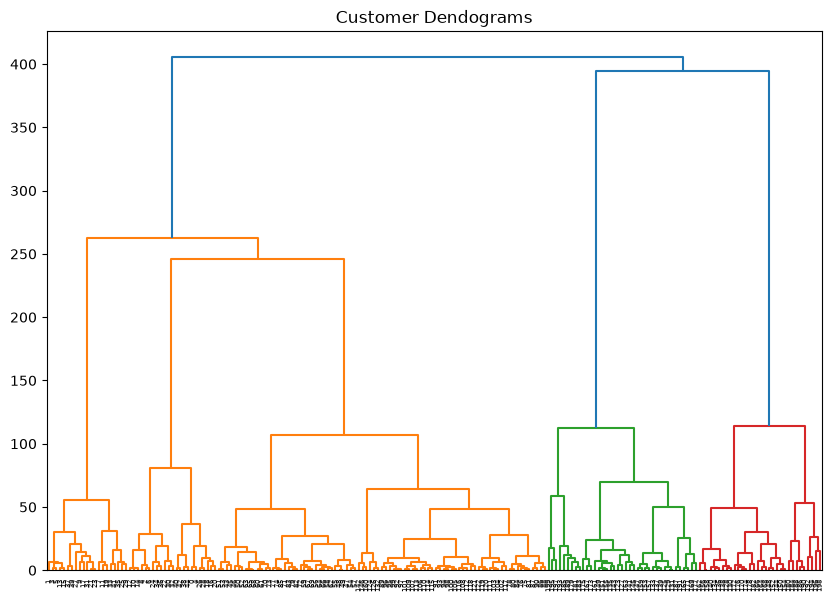

In [10]:
plt.figure(figsize=(10,7))
plt.title("Customer Dendograms")
dend = shc.dendrogram(shc.linkage(data,method='ward'))

In [12]:
from sklearn.cluster import AgglomerativeClustering

cluster = AgglomerativeClustering(n_clusters=5,linkage='ward')
labels_ = cluster.fit_predict(data)

In [13]:
labels_

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 1,
       4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 2, 0, 2, 0, 2,
       1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 1, 2, 0, 2, 1, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2])

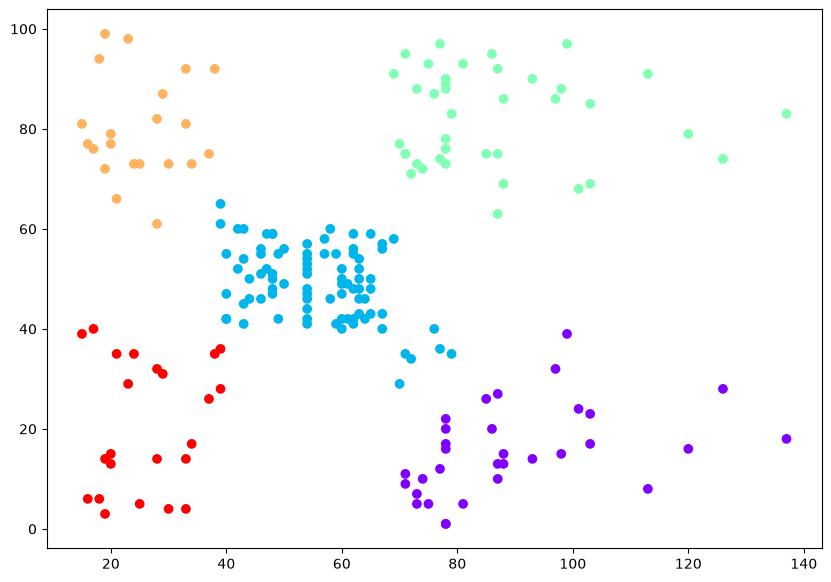

In [14]:
plt.figure(figsize=(10,7))
plt.scatter(data[:,0],data[:,1],c=cluster.labels_,cmap='rainbow')

Benifit :<br> 
1. Wide variety of dataset can be used to make clusters (widey applicable)
2. Dendogram : visualization helps to have know which point is near to which , giving more insite on the data<br>
Limitation <br>
1. Cannot be used in large number of dataset , as we calculate the proximity matrix and if there are more than 12 number of fetures then its required a large number of space in ram which is not possible normally 